### EDA in Action

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
OUTPUT = Path("../output")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)

df = pd.read_csv(OUTPUT / "renewals_clean.csv", parse_dates=["renewal_date"])
sns.set_theme(style="whitegrid")

NUM = ["employee_count", "seats_purchased", "seats_purchased",
       "discount_pct", "annual_contract_value", "avg_seat_utilization", "utilization_trend",
       "avg_feature_adoption", "support_cases_12m", "sev1_cases_12m", "nps_score"]

### Univariate Analysis

In [7]:
print(df["renewal_status"].value_counts().to_dict(), " | Churn Rate : ",
      round(df["churned"].mean(), 3))

print(f"ACV Churned : ${df.loc[df.churned == 1, "annual_contract_value"].sum() / 1e6:.1f}M of ",
      f"${df["annual_contract_value"].sum() / 1e6:.1f}M")

{'Renewed': 615, 'Churned': 180}  | Churn Rate :  0.226
ACV Churned : $48.1M of  $262.1M


In [8]:
summ = df[NUM].describe().T[["mean", "50%", "std", "min", "max"]]
summ["skew"] = df[NUM].skew()

print(summ.round(2))

                            mean       50%        std      min         max  skew
employee_count           4482.94    706.00    9568.63    20.00    59883.00  3.23
seats_purchased          1241.09    320.00    2148.10    15.00    11790.00  2.72
seats_purchased          1241.09    320.00    2148.10    15.00    11790.00  2.72
discount_pct               14.73     13.60       6.97     0.00       31.80  0.24
annual_contract_value  329643.60  85072.79  594016.41  2436.42  4169814.56  2.98
avg_seat_utilization        0.65      0.66       0.12     0.30        0.98 -0.11
utilization_trend          -0.03     -0.02       0.14    -0.58        0.42 -0.39
avg_feature_adoption       61.07     61.20       6.58    43.70       79.30 -0.04
support_cases_12m           7.01      6.00       4.08     0.00       32.00  1.53
sev1_cases_12m              0.29      0.00       0.55     0.00        3.00  2.05
nps_score                  37.27     38.00      15.15   -16.00       84.00 -0.15


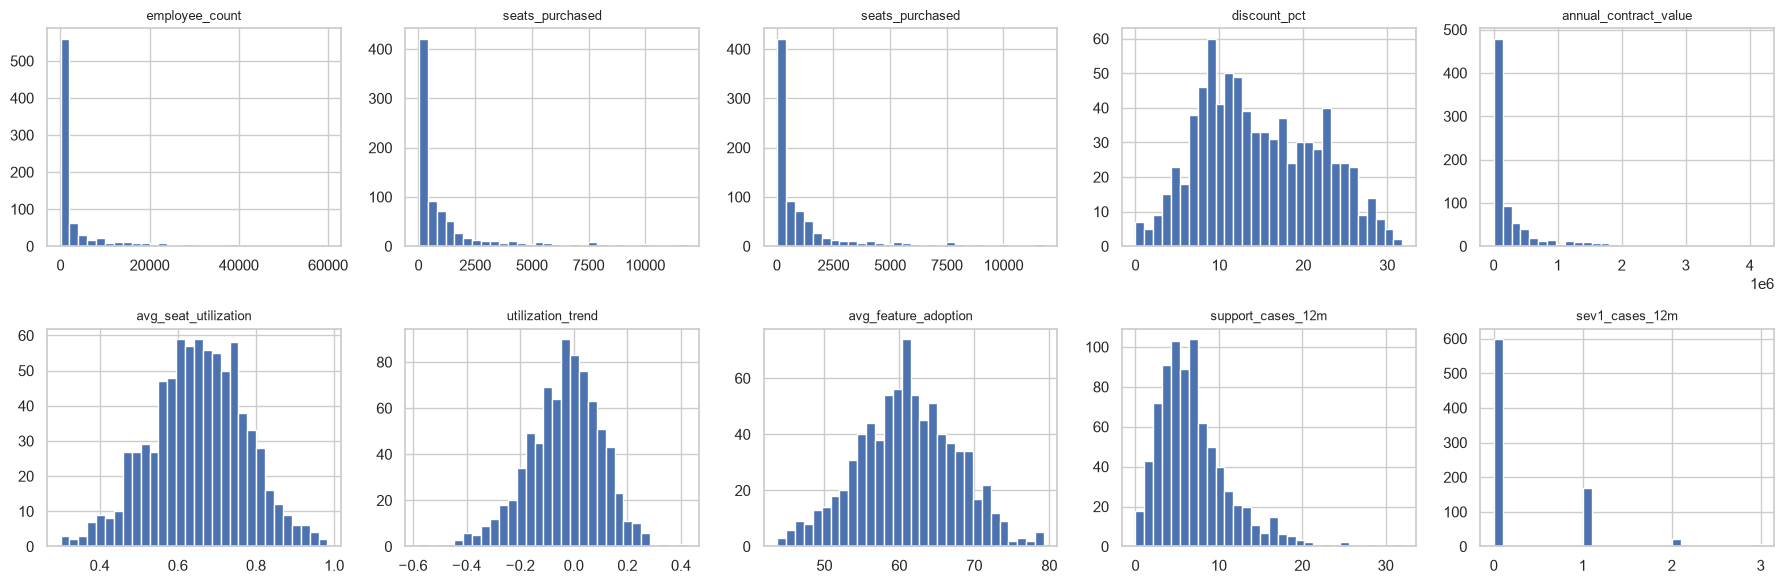

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, col in zip(axes.ravel(), NUM):
    ax.hist(df[col], bins=30)
    ax.set_title(col, fontsize=9)
    
fig.tight_layout()
plt.show()

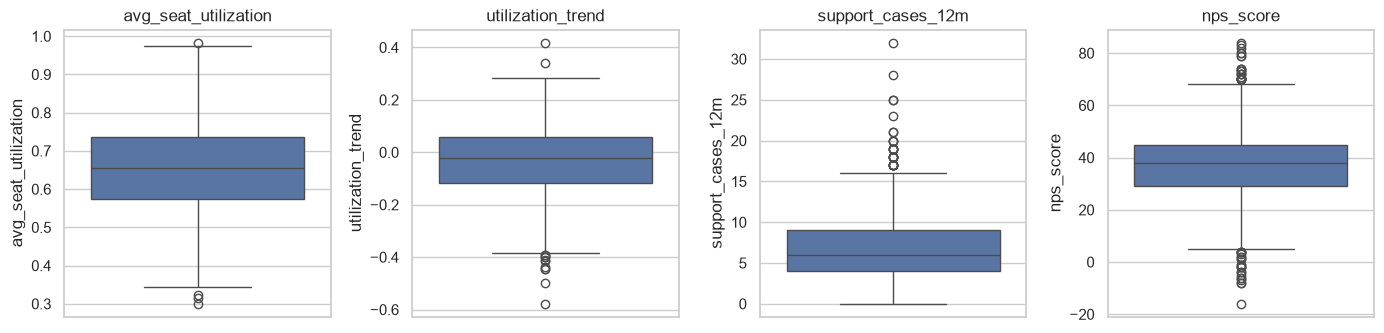

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for ax, col in zip(axes, ["avg_seat_utilization", "utilization_trend", "support_cases_12m", "nps_score"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
    
fig.tight_layout()
plt.show()

In [12]:
CATEGORICAL_COLUMNS = ["segment", "region",
                       "tier", "product", "csm_health", "auto_renew"]

for column in CATEGORICAL_COLUMNS:
    print(column, df[column].value_counts(normalize=True).round(2).to_dict())

segment {'SMB': 0.36, 'Mid-Market': 0.29, 'Enterprise': 0.2, 'Public Sector': 0.15}
region {'Americas': 0.48, 'EMEA': 0.28, 'APJC': 0.24}
tier {'Essentials': 0.44, 'Advantage': 0.39, 'Premier': 0.17}
product {'Corvana Collaborate': 0.4, 'Corvana SecureEdge': 0.27, 'Corvana NetOps Cloud': 0.21, 'Corvana Observe': 0.12}
csm_health {'No CSM': 0.5, 'Green': 0.24, 'Red': 0.16, 'Amber': 0.09}
auto_renew {False: 0.61, True: 0.39}


### Bivariate Analysis - Churn Rate by Category

In [13]:
spread = {}
CATEGORICAL_COLUMNS = ["segment", "region",
                       "tier", "product", "csm_health", "auto_renew", "nps_missing", "term_months"]

for col in CATEGORICAL_COLUMNS:
    rates = (df.groupby(col)["churned"]
               .agg(churn_rate="mean", count="size")
               .sort_values("churn_rate", ascending=False))
    print(f"\n{col}")
    print(rates.round(3).to_string())
    spread[col] = rates["churn_rate"].max() - rates["churn_rate"].min()

print("\nFeatures ranked by churn-rate spread (max - min):")
print(pd.Series(spread, name="spread").sort_values(
    ascending=False).round(3).to_string())


segment
               churn_rate  count
segment                         
SMB                 0.270    289
Mid-Market          0.233    232
Enterprise          0.186    156
Public Sector       0.161    118

region
          churn_rate  count
region                     
Americas       0.243    379
APJC           0.214    192
EMEA           0.210    224

tier
            churn_rate  count
tier                         
Essentials       0.276    351
Advantage        0.203    311
Premier          0.150    133

product
                      churn_rate  count
product                                
Corvana SecureEdge         0.247    215
Corvana NetOps Cloud       0.241    166
Corvana Collaborate        0.211    318
Corvana Observe            0.208     96

csm_health
            churn_rate  count
csm_health                   
Red              0.458    131
No CSM           0.249    401
Amber            0.111     72
Green            0.063    191

auto_renew
            churn_rate  count
auto_r

### Bivariate Analysis - Numerical Features vs Churn

In [14]:
NUM_SELECTED = ["discount_pct", "annual_contract_value", "avg_seat_utilization", "utilization_trend",
                "avg_feature_adoption", "support_cases_12m", "nps_score"]
OUTCOME_ORDER = ["Renewed", "Churned"]
OUTCOME_COLORS = {"Renewed": "#2a78d6", "Churned": "#eb6834"}

# diff_std = gap in units of the feature's std, so features on different scales are comparable
means = df.groupby("renewal_status")[NUM_SELECTED].mean().T[OUTCOME_ORDER]
means["diff"] = means["Churned"] - means["Renewed"]
means["diff_std"] = means["diff"] / df[NUM_SELECTED].std()

print(means.sort_values("diff_std", key=abs, ascending=False).round(2))

renewal_status           Renewed    Churned      diff  diff_std
utilization_trend          -0.01      -0.13     -0.12     -0.89
avg_seat_utilization        0.67       0.60     -0.07     -0.61
avg_feature_adoption       61.77      58.70     -3.06     -0.47
nps_score                  38.35      33.55     -4.80     -0.32
discount_pct               14.99      13.83     -1.17     -0.17
annual_contract_value  347882.33  267327.95 -80554.38     -0.14
support_cases_12m           7.04       6.89     -0.14     -0.04


In [15]:
# nps_score was imputed during cleaning; nps_missing == 0 marks customers who actually answered
answered = df[df["nps_missing"] == 0]

nps = pd.DataFrame({
    "all_rows": df.groupby("renewal_status")["nps_score"].mean(),
    "answered_only": answered.groupby("renewal_status")["nps_score"].mean(),
    "answered_count": answered.groupby("renewal_status").size(),
    "response_rate": 1 - df.groupby("renewal_status")["nps_missing"].mean(),
}).loc[OUTCOME_ORDER]

print(f"Survey respondents: {len(answered)} of {len(df)} ({len(answered) / len(df):.0%})")
print(nps.round(2))

Survey respondents: 658 of 795 (83%)
                all_rows  answered_only  answered_count  response_rate
renewal_status                                                        
Renewed            38.35          38.40             544           0.88
Churned            33.55          30.97             114           0.63


In [16]:
# NUM lists seats_purchased twice; dict.fromkeys de-duplicates while keeping order
corr = df[list(dict.fromkeys(NUM))].corrwith(df["churned"])
corr["nps_score (answered only)"] = answered["nps_score"].corr(answered["churned"])

print("Correlation with churned (sorted by strength):")
print(corr.sort_values(key=abs, ascending=False).round(3).to_string())

Correlation with churned (sorted by strength):
utilization_trend           -0.372
avg_seat_utilization        -0.254
avg_feature_adoption        -0.195
nps_score (answered only)   -0.169
nps_score                   -0.133
sev1_cases_12m               0.094
discount_pct                -0.070
annual_contract_value       -0.057
seats_purchased             -0.054
employee_count              -0.037
support_cases_12m           -0.015


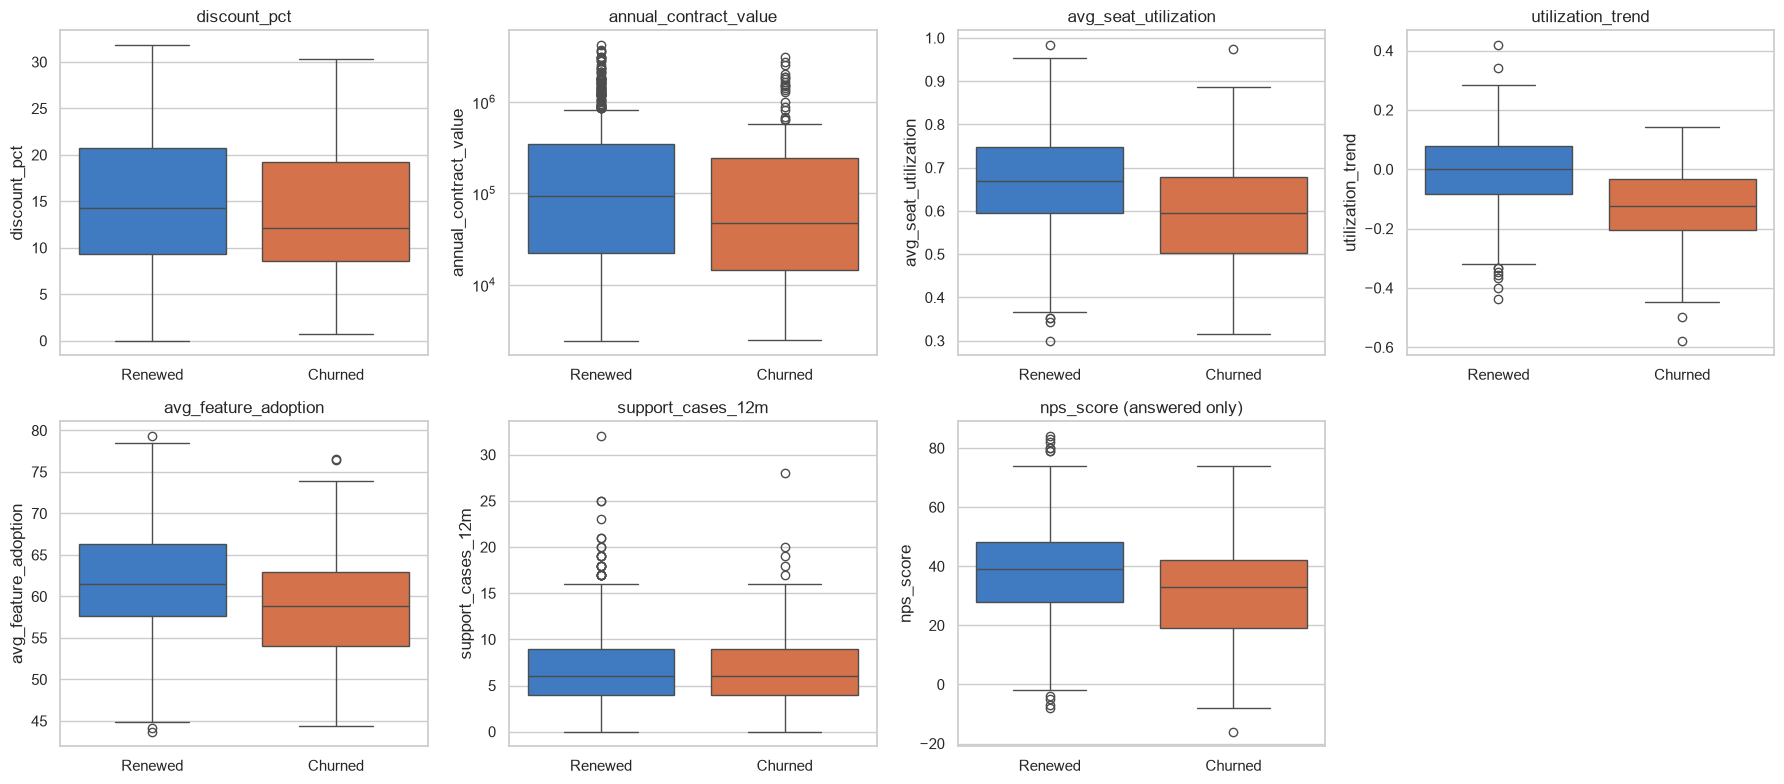

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, col in zip(axes.ravel(), NUM_SELECTED):
    data = answered if col == "nps_score" else df
    sns.boxplot(data=data, x="renewal_status", y=col, hue="renewal_status", order=OUTCOME_ORDER,
                palette=OUTCOME_COLORS, legend=False, ax=ax)
    ax.set_title(f"{col} (answered only)" if col == "nps_score" else col)
    ax.set_xlabel("")

axes[0, 1].set_yscale("log")    # annual_contract_value is heavily right-skewed
axes.ravel()[-1].set_visible(False)

fig.tight_layout()
plt.show()

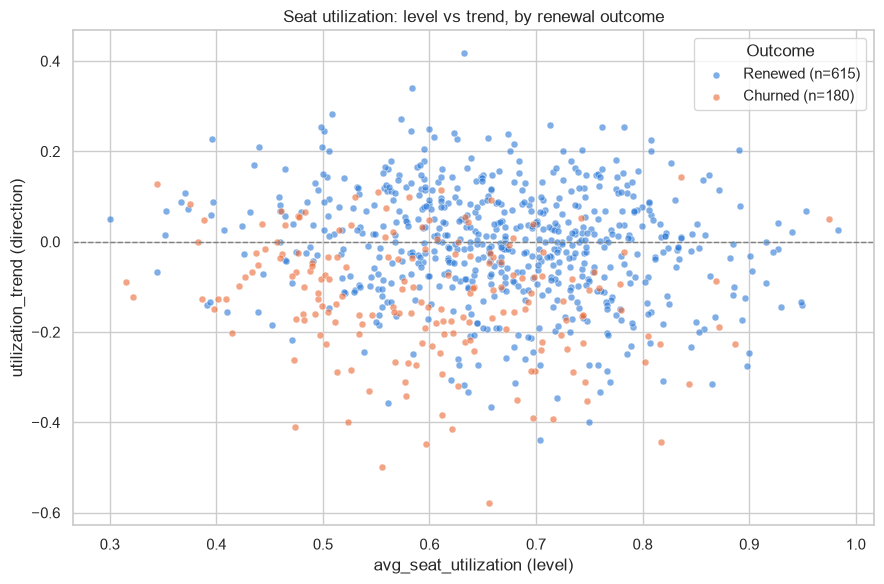

In [18]:
fig, ax = plt.subplots(figsize=(9, 6))

for status in OUTCOME_ORDER:
    sub = df[df["renewal_status"] == status]
    ax.scatter(sub["avg_seat_utilization"], sub["utilization_trend"], s=25, alpha=0.6,
               color=OUTCOME_COLORS[status], edgecolors="white", linewidths=0.5,
               label=f"{status} (n={len(sub)})")

ax.axhline(0, color="grey", linewidth=1, linestyle="--")
ax.set_xlabel("avg_seat_utilization (level)")
ax.set_ylabel("utilization_trend (direction)")
ax.set_title("Seat utilization: level vs trend, by renewal outcome")
ax.legend(title="Outcome")

fig.tight_layout()
plt.show()

### Multivariate Analysis

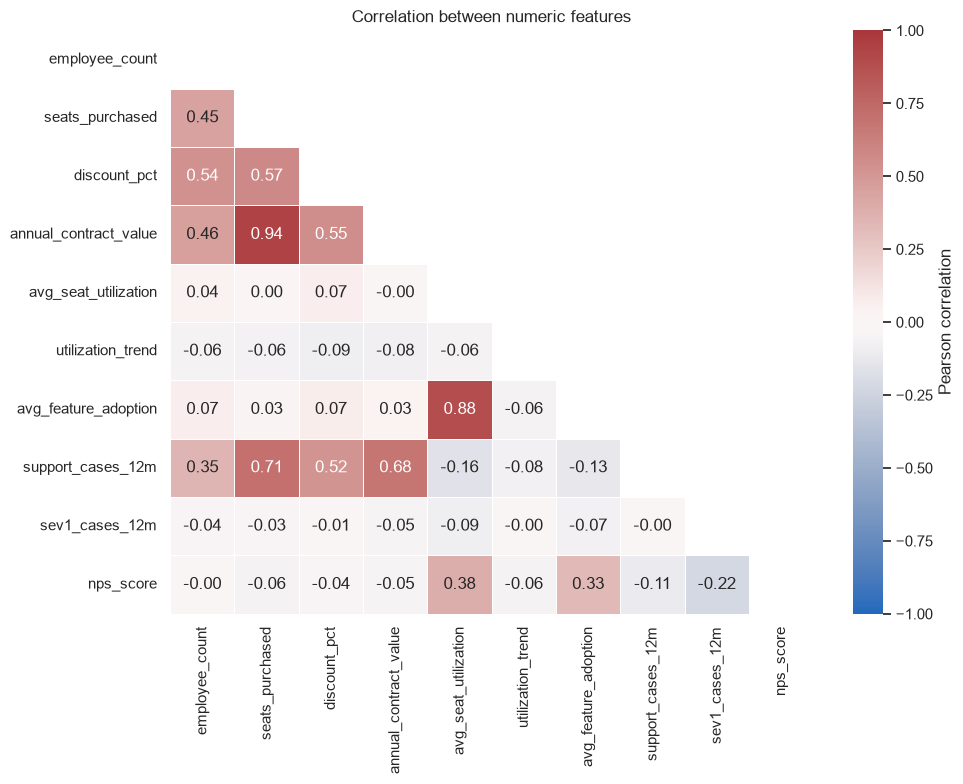

Four strongest pairs:
seats_purchased        annual_contract_value    0.940
avg_seat_utilization   avg_feature_adoption     0.885
seats_purchased        support_cases_12m        0.709
annual_contract_value  support_cases_12m        0.683


In [19]:
corr_matrix = df[list(dict.fromkeys(NUM))].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, mask=np.triu(np.ones_like(corr_matrix, dtype=bool)),
            annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.grid(False)
ax.set_title("Correlation between numeric features")
fig.tight_layout()
plt.show()

# keep each pair once (upper triangle, no diagonal), then rank by absolute strength
pairs = (corr_matrix.where(np.triu(np.ones_like(corr_matrix, dtype=bool), k=1))
                    .stack()
                    .rename("correlation"))

print("Four strongest pairs:")
print(pairs.sort_values(key=abs, ascending=False).head(4).round(3).to_string())

In [20]:
def churn_pivot(index, columns):
    """Churn-rate and count pivot tables, each with an 'All' row/column."""
    kw = dict(index=index, columns=columns, values="churned",
              margins=True, margins_name="All", observed=False)
    return df.pivot_table(aggfunc="mean", **kw), df.pivot_table(aggfunc="count", **kw)

SEGMENT_ORDER = ["SMB", "Mid-Market", "Enterprise", "Public Sector", "All"]
TIER_ORDER = ["Essentials", "Advantage", "Premier", "All"]

rate, count = churn_pivot("segment", "tier")

print("Churn rate by segment x tier:")
print(rate.loc[SEGMENT_ORDER, TIER_ORDER].round(3))
print("\nCount by segment x tier:")
print(count.loc[SEGMENT_ORDER, TIER_ORDER])

Churn rate by segment x tier:
tier           Essentials  Advantage  Premier    All
segment                                             
SMB                 0.314      0.180    0.250  0.270
Mid-Market          0.294      0.198    0.147  0.233
Enterprise          0.148      0.246    0.133  0.186
Public Sector       0.118      0.193    0.148  0.161
All                 0.276      0.203    0.150  0.226

Count by segment x tier:
tier           Essentials  Advantage  Premier  All
segment                                           
SMB                   188         89       12  289
Mid-Market            102         96       34  232
Enterprise             27         69       60  156
Public Sector          34         57       27  118
All                   351        311      133  795


In [21]:
df["util_band"] = pd.cut(df["avg_seat_utilization"], bins=[0, 0.5, 0.7, np.inf], right=False,
                         labels=["Low (<50%)", "Medium (50-70%)", "High (70%+)"])
df["trend_band"] = pd.cut(df["utilization_trend"], bins=[-np.inf, -0.05, 0.05, np.inf], right=False,
                          labels=["Declining", "Flat", "Growing"])

rate, count = churn_pivot("util_band", "auto_renew")

print("Churn rate by utilization band x auto-renew:")
print(rate.round(3))
print("\nCount by utilization band x auto-renew:")
print(count)

Churn rate by utilization band x auto-renew:
auto_renew       False   True    All
util_band                           
Low (<50%)       0.558  0.405  0.494
Medium (50-70%)  0.283  0.189  0.246
High (70%+)      0.141  0.072  0.115
All              0.261  0.173  0.226

Count by utilization band x auto-renew:
auto_renew       False  True  All
util_band                        
Low (<50%)          52    37   89
Medium (50-70%)    254   164  418
High (70%+)        177   111  288
All                483   312  795


In [22]:
MIN_COUNT = 15    # ignore combinations too small to give a reliable churn rate

combos = (df.groupby(["util_band", "trend_band"], observed=True)["churned"]
            .agg(churn_rate="mean", count="size")
            .sort_values("churn_rate", ascending=False))

print(f"Utilization band x trend band, combinations with at least {MIN_COUNT} contracts (riskiest first):")
print(combos[combos["count"] >= MIN_COUNT].round(3).to_string())

small = combos[combos["count"] < MIN_COUNT]
if len(small):
    print(f"\nExcluded (fewer than {MIN_COUNT} contracts):")
    print(small.round(3).to_string())

Utilization band x trend band, combinations with at least 15 contracts (riskiest first):
                            churn_rate  count
util_band       trend_band                   
Low (<50%)      Declining        0.750     36
                Flat             0.440     25
Medium (50-70%) Declining        0.424    170
High (70%+)     Declining        0.228    123
Low (<50%)      Growing          0.214     28
Medium (50-70%) Flat             0.185    130
                Growing          0.059    118
High (70%+)     Growing          0.043     69
                Flat             0.021     96


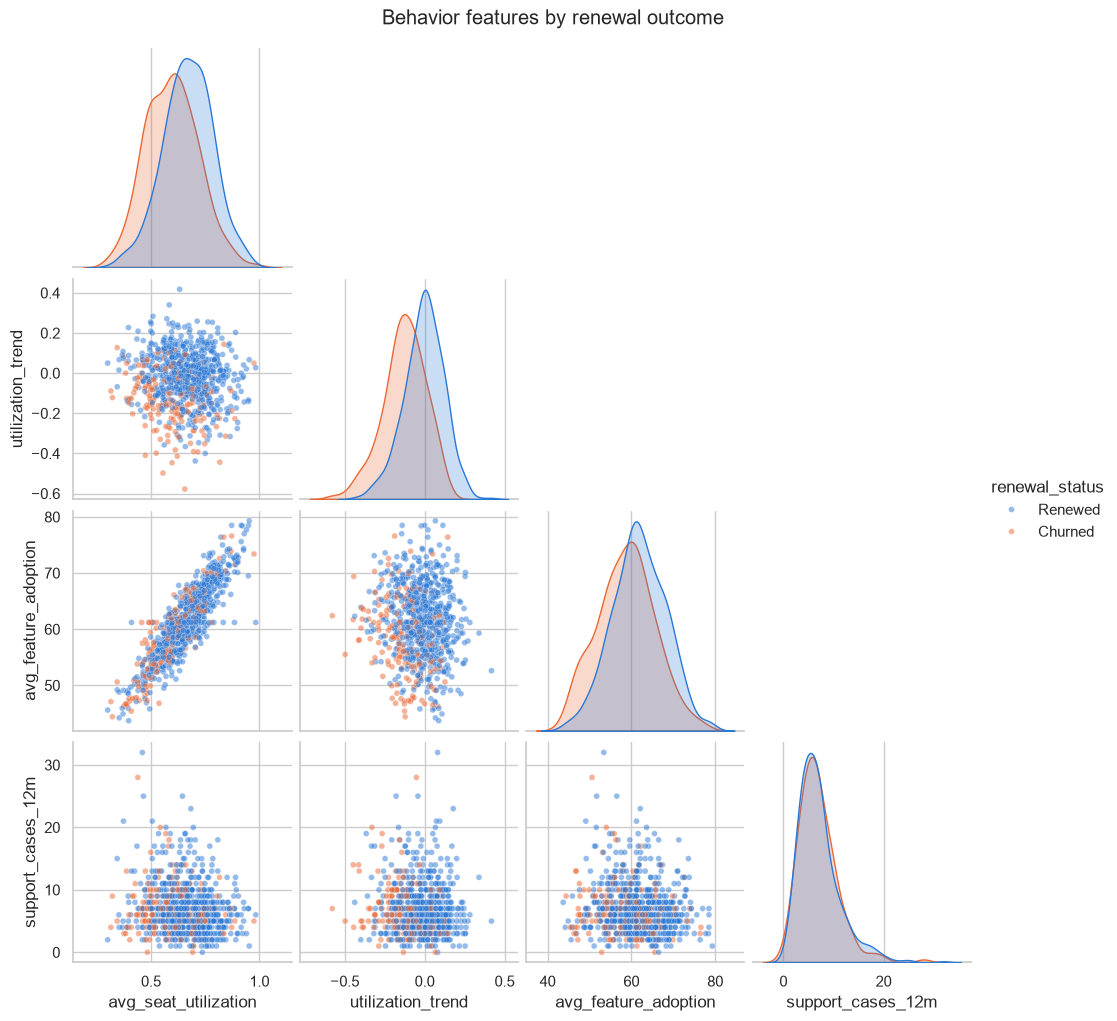

In [23]:
BEHAVIOR = ["avg_seat_utilization", "utilization_trend", "avg_feature_adoption", "support_cases_12m"]

# common_norm=False scales each outcome's density on its own, so the smaller Churned group stays readable
grid = sns.pairplot(df, vars=BEHAVIOR, hue="renewal_status", hue_order=OUTCOME_ORDER,
                    palette=OUTCOME_COLORS, corner=True, diag_kind="kde",
                    diag_kws={"common_norm": False},
                    plot_kws={"s": 18, "alpha": 0.5, "edgecolor": "white", "linewidth": 0.3})
grid.figure.suptitle("Behavior features by renewal outcome", y=1.02)
plt.show()